**Parte 1**

In [83]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import simpson
from scipy.special import jv

pi = np.pi

In [ ]:
num = 300  ### Número de pontos
if num % 2 == 0: num += 1

lamb = 100
a = 50*lamb

k = (2*pi)/lamb

f = lambda rho_s,phi_s : rho_s * np.exp(1j*k*rho_s*np.sin(theta)*np.cos(phi-phi_s))

### Intervalo de análise
x1 = 0
x2 = a
y1 = 0
y2 = 2*pi

theta = np.linspace(0,pi,num)
phi = np.linspace(0,pi,num)

rho_l = np.linspace(x1,x2,num)
phi_l = np.linspace(y1,y2,num)

# eixos para broadcasting: (phi, rho', phi')
PHI  = phi[:, None, None]
RHO  = rho_l[None, :, None]
PHIL = phi_l[None, None, :]

I = np.zeros((num, num), dtype=complex)   # I[theta, phi]

for i, th in enumerate(theta):
    integrando = RHO**2 * np.exp(1j*k*RHO*np.sin(th)*np.cos(PHI - PHIL))
    # integra em phi' (eixo 2) e depois em rho' (eixo 1)
    I[i, :] = simpson(simpson(integrando, x=phi_l, axis=2), x=rho_l, axis=1)

TH, PH = np.meshgrid(theta, phi, indexing='ij')

E_theta =  np.cos(TH)*np.cos(PH)*I
E_phi   = -np.sin(PH)*I

E_theta = np.abs(E_theta)/np.max(E_theta)
E_theta = 20*np.log10(E_theta+1e-12)

E_phi = np.abs(E_phi)/np.max(E_phi)
E_phi = 20*np.log10(E_phi+1e-12)

Solução Analítica

In [85]:
num2 = 500  ### Número de pontos
theta2 = np.linspace(0,pi,num2)
phi2 = np.linspace(0,pi,num2)

TH, PH = np.meshgrid(theta2, phi2, indexing='ij')

u = k*np.sin(theta2)          # vetor em theta
x = u*a

# --- Caso A: peso rho' ---
I_theta = np.where(x > 1e-8,
                   2*np.pi*a*jv(1, x)/np.where(x > 1e-8, u, 1),
                   np.pi*a**2)                  # limite em u -> 0

I = np.tile(I_theta[:, None], (1, num2))         # I[theta, phi], independe de phi

Ea_theta =  np.cos(TH)*np.cos(PH)*I
Ea_phi   = -np.sin(PH)*I

norm = np.max(np.abs(Ea_theta))                 # ou max das duas componentes
Ea_theta = 20*np.log10(np.abs(Ea_theta)/norm + 1e-12)
Ea_phi   = 20*np.log10(np.abs(Ea_phi)/norm + 1e-12)


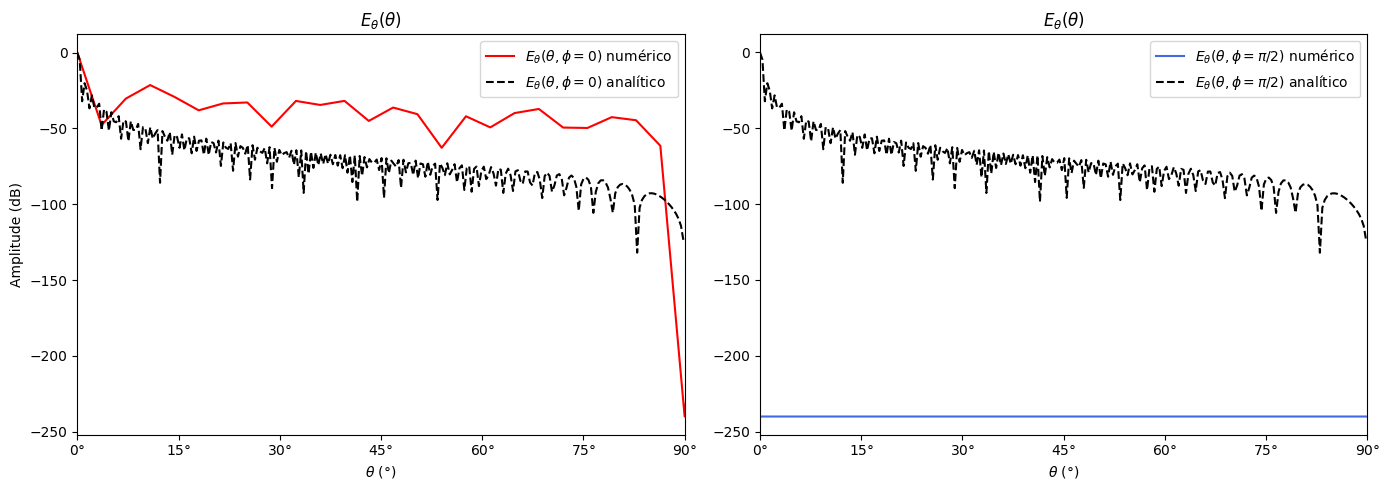

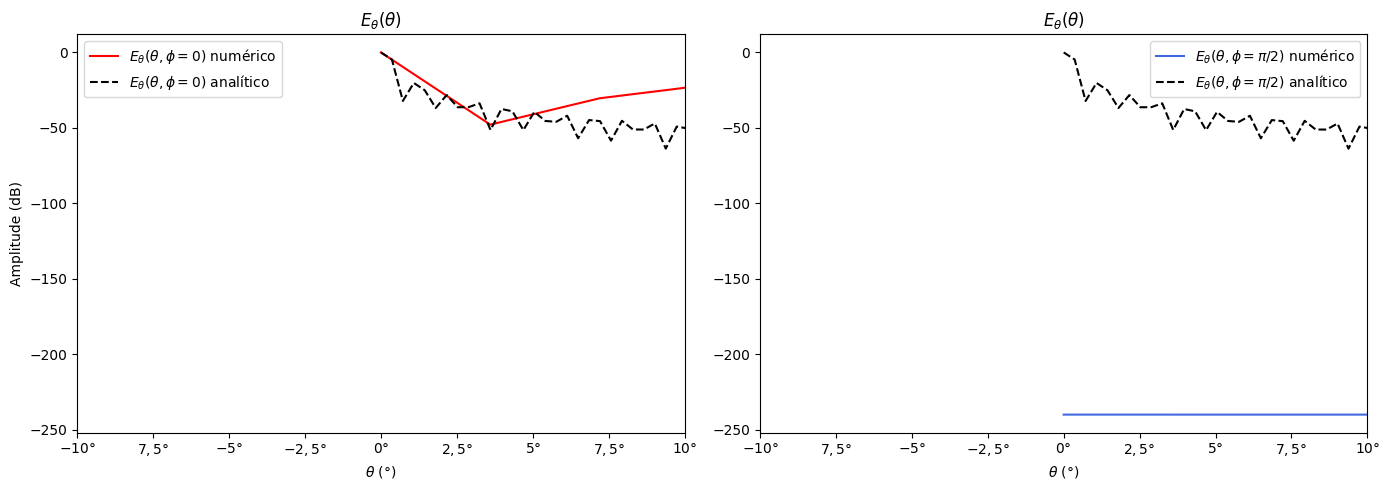

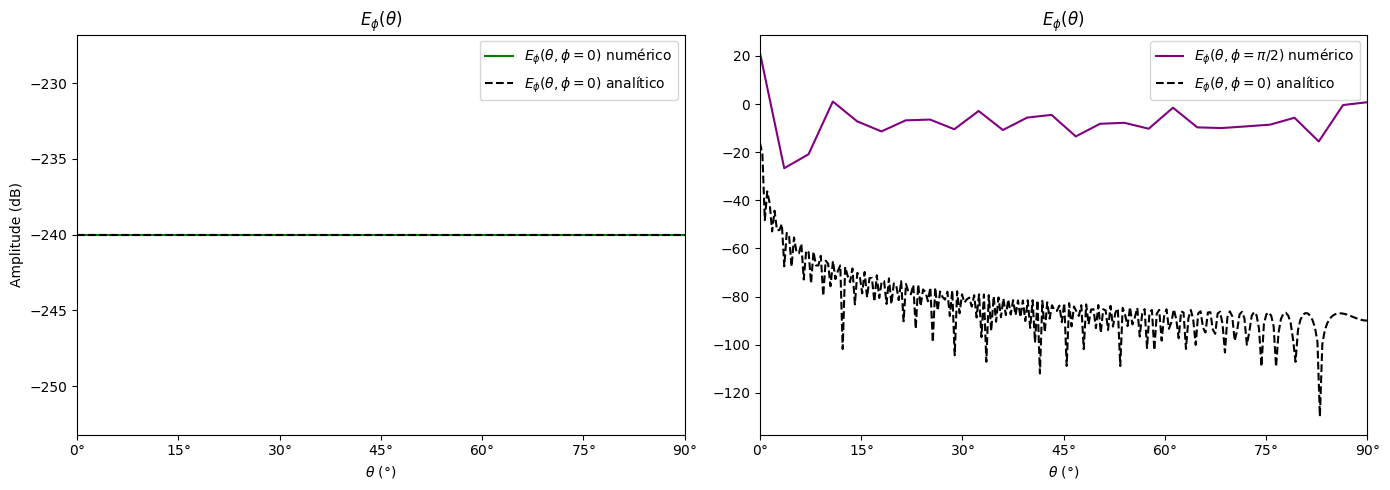

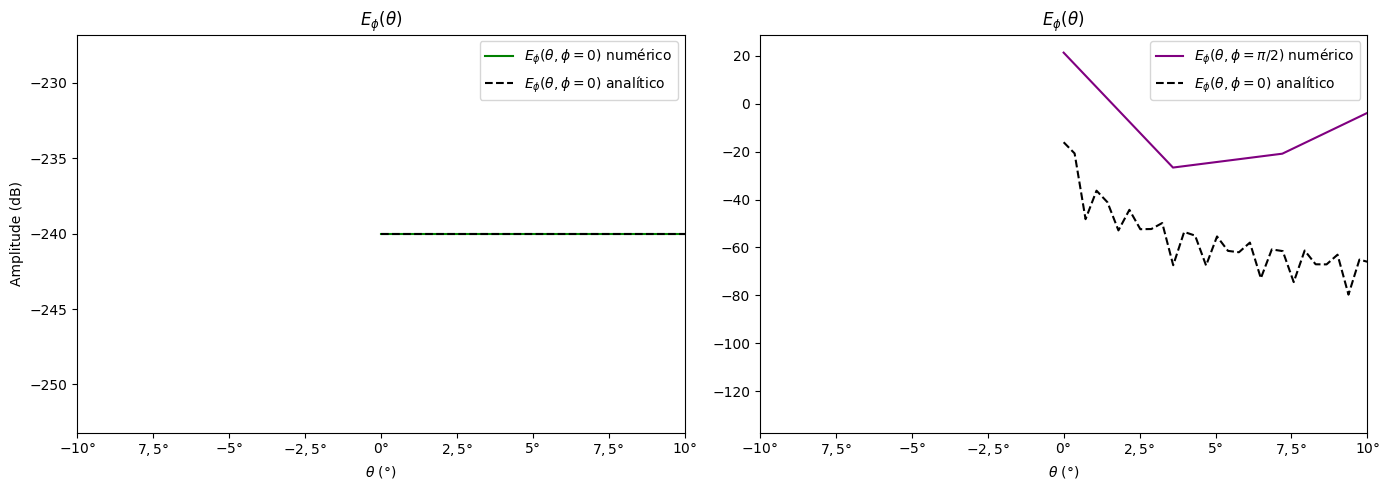

In [86]:
fig, ax = plt.subplots(1,2,figsize=(14,5))

ax[0].set_title(r'$E_\theta(\theta)$')
ax[1].set_title(r'$E_\theta(\theta)$')

ax[0].plot(theta,np.real(E_theta[:,0]),label=r'$E_{\theta}(\theta,\phi=0)$ numérico',color='red')
ax[0].plot(theta2,np.real(Ea_theta[:,0]),label=r'$E_{\theta}(\theta,\phi=0)$ analítico',color='black',ls='--')

ax[1].plot(theta,np.real(E_theta[:,int(num/2)]),label=r'$E_{\theta}(\theta,\phi=\pi/2)$ numérico',color='royalblue')
ax[1].plot(theta2,np.real(Ea_theta[:,int(num/2)]),label=r'$E_{\theta}(\theta,\phi=\pi/2)$ analítico',color='black',ls='--')

for i in [0,1]:
    ax[i].set_xticks([0,np.pi/12,np.pi/6,np.pi/4,np.pi/3,(5*np.pi)/12,np.pi/2],
                     [ r"$0°$", r"$15°$",r"$30°$",r"$45°$",r"$60°$",r"$75°$",r"$90°$"])
    ax[i].set_xlim(0,pi/2)
    ax[i].set_xlabel(r'$\theta$ (°)')
    ax[i].legend()

ax[0].set_ylabel('Amplitude (dB)')

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1,2,figsize=(14,5))

ax[0].set_title(r'$E_\theta(\theta)$')
ax[1].set_title(r'$E_\theta(\theta)$')

ax[0].plot(theta,np.real(E_theta[:,0]),label=r'$E_{\theta}(\theta,\phi=0)$ numérico',color='red')
ax[0].plot(theta2,np.real(Ea_theta[:,0]),label=r'$E_{\theta}(\theta,\phi=0)$ analítico',color='black',ls='--')

ax[1].plot(theta,np.real(E_theta[:,int(num/2)]),label=r'$E_{\theta}(\theta,\phi=\pi/2)$ numérico',color='royalblue')
ax[1].plot(theta2,np.real(Ea_theta[:,int(num/2)]),label=r'$E_{\theta}(\theta,\phi=\pi/2)$ analítico',color='black',ls='--')

for i in [0,1]:
    ax[i].set_xticks([ -pi/18,-1.5*pi/36,-pi/36,-0.5*pi/36 ,0,0.5*pi/36,pi/36,1.5*pi/36, pi/18],
                     [r"$-10°$",r"$7,5°$",r"$-5°$",r"$-2,5°$" ,r"$0°$",r"$2,5°$",r"$5°$",r"$7,5°$", r"$10°$"])
    ax[i].set_xlim(-pi/18,pi/18)
    ax[i].set_xlabel(r'$\theta$ (°)')
    ax[i].legend()


ax[0].set_ylabel('Amplitude (dB)')

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1,2,figsize=(14,5))

ax[0].set_title(r'$E_\phi(\theta)$')
ax[1].set_title(r'$E_\phi(\theta)$')

ax[0].plot(theta,np.real(E_phi[:,0]),label=r'$E_{\phi}(\theta,\phi=0)$ numérico',color='green')
ax[0].plot(theta2,np.real(Ea_phi[:,0]),label=r'$E_{\phi}(\theta,\phi=0)$ analítico',color='black',ls='--')

ax[1].plot(theta,np.real(E_phi[:,int(num/2)]),label=r'$E_{\phi}(\theta,\phi=\pi/2)$ numérico',color='purple')
ax[1].plot(theta2,np.real(Ea_phi[:,int(num/2)]),label=r'$E_{\phi}(\theta,\phi=0)$ analítico',color='black',ls='--')

for i in [0,1]:
    ax[i].set_xticks([0,np.pi/12,np.pi/6,np.pi/4,np.pi/3,(5*np.pi)/12,np.pi/2],
                     [ r"$0°$", r"$15°$",r"$30°$",r"$45°$",r"$60°$",r"$75°$",r"$90°$"])
    ax[i].set_xlim(0,pi/2)
    ax[i].legend()
    ax[i].set_xlabel(r'$\theta$ (°)')

ax[0].set_ylabel('Amplitude (dB)')

plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1,2,figsize=(14,5))

ax[0].set_title(r'$E_\phi(\theta)$')
ax[1].set_title(r'$E_\phi(\theta)$')

ax[0].plot(theta,np.real(E_phi[:,0]),label=r'$E_{\phi}(\theta,\phi=0)$ numérico',color='green')
ax[0].plot(theta2,np.real(Ea_phi[:,0]),label=r'$E_{\phi}(\theta,\phi=0)$ analítico',color='black',ls='--')

ax[1].plot(theta,np.real(E_phi[:,int(num/2)]),label=r'$E_{\phi}(\theta,\phi=\pi/2)$ numérico',color='purple')
ax[1].plot(theta2,np.real(Ea_phi[:,int(num/2)]),label=r'$E_{\phi}(\theta,\phi=0)$ analítico',color='black',ls='--')

for i in [0,1]:
    ax[i].set_xticks([ -pi/18,-1.5*pi/36,-pi/36,-0.5*pi/36 ,0,0.5*pi/36,pi/36,1.5*pi/36, pi/18],
                     [r"$-10°$",r"$7,5°$",r"$-5°$",r"$-2,5°$" ,r"$0°$",r"$2,5°$",r"$5°$",r"$7,5°$", r"$10°$"])
    ax[i].set_xlim(-pi/18,pi/18)
    ax[i].set_xlabel(r'$\theta$ (°)')
    ax[i].legend()

ax[0].set_ylabel('Amplitude (dB)')

plt.tight_layout()
plt.show()
